# Flow Matching Training

Welcome to the flow matching demo! In this notebook, we will show the process of training a 
flow matching model. 

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from abc import ABC, abstractmethod

import xarray as xr
import torch
from torch import Tensor
from matplotlib import pyplot as plt

from src.config import load_config
from src.config.schema import SchedulerConfig

In [2]:
CONFIG_PATH = str(Path.cwd().parent) + "/src/config/config.yaml"
DATA_PATH = "/gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/data/jakarta128_8km_to_2km_imperfect"

PREDICTORS_PATH = DATA_PATH + "/predictors"
TARGETS_PATH = DATA_PATH + "/targets"
STATIC_PATH = DATA_PATH + "/static/static_128jakarta_sqrt_normalised.nc"
OUTPUT_PATH = ...

In [3]:
NUM_WORKERS = 8
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

config = load_config(CONFIG_PATH)

Using device: cuda:0


## Load data

First, we will load the predictor and the target dataset. 

We use data from Singapore's Third National Climate Change Study (V3). V3 provides high-resolution climate projections over Southeast Asia by applying a two-stage dynamical downcaling approach; a collection of six CMIP6 GCMs (75-250 km resolution) are downscaled to 8km over a large region encompassing most of Southeast Asia, and subsequently to 2 km over a smaller inner domain covering Singapore, the Malay Peninsula and Sumatra. The SINGV-RCM regional climate model was used for both downcaling stages. 

In this notebook, we train a model to predict 2 km precipitation from 8 km atmospheric fields, over a cutout centred on [Jakarta/Singapore]. 

In [4]:
def _parse_years(year_list: list[str | int]) -> list[int]:
    """Parses a list of years/ranges into a list of integers."""
    parsed_years: list[int] = []
    for item in year_list:
        if isinstance(item, str) and "-" in item:
            start, end = map(int, item.split("-"))
            parsed_years.extend(range(start, end + 1))
        else:
            parsed_years.append(int(item))
    return sorted(list(set(parsed_years)))


def load_dataset(path: str, variables: list[str], years: list[int]) -> xr.Dataset:
    """Lazily loads dataset for the given variables and years."""
    ds_list: list[xr.DataArray] = []
    for var_name in variables:
        var_path = f"{path}/{var_name}.zarr"
        ds = xr.open_zarr(var_path, consolidated=True, chunks="auto")
        ds_list.append(ds[var_name])

    ds = xr.merge(ds_list)
    ds = ds.sel(time=ds.time.dt.year.isin(years))
    return ds

In [5]:
train_years = _parse_years(config.training.years)
val_years = _parse_years(config.validation.years)

predictors_ds = load_dataset(PREDICTORS_PATH, list(config.predictors.keys()), train_years)
targets_ds = load_dataset(TARGETS_PATH, list(config.targets.keys()), train_years)

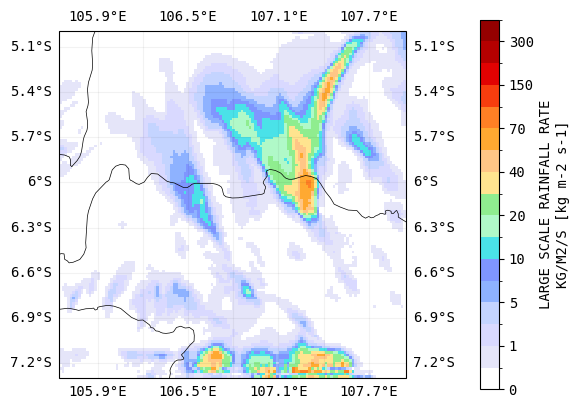

In [6]:
from src.plotting import plot_field


plot_field(
    ds=targets_ds,
    time_idx=0,
    variable="pr",
    units="mm day-1",
)

## Fit transforms

In [8]:
from src.transforms import Transform, fit_transforms, save_transforms

In [9]:
predictor_transforms = fit_transforms(config, predictors_ds, groups=["predictors"])
target_transforms = fit_transforms(config, targets_ds, groups=["targets"])

transforms: dict[str, dict[str, Transform]] = {
    "predictors": predictor_transforms["predictors"],
    "targets": target_transforms["targets"],
}

save_transforms(transforms, f"{OUTPUT_PATH}/transforms.json")

## Initialise Datasets and Dataloaders

In [10]:
from src.dataset import V3Dataset

In [11]:
training_dataset = V3Dataset(
    predictors_path=PREDICTORS_PATH,
    targets_path=TARGETS_PATH,
    config=config,
    years=train_years,
    transforms=transforms,
    static_path=STATIC_PATH,
)
validation_dataset = V3Dataset(
    predictors_path=PREDICTORS_PATH,
    targets_path=TARGETS_PATH,
    config=config,
    years=val_years,
    transforms=transforms,
    static_path=STATIC_PATH,
)

batch_size = config.training.batch_size
training_dataloader = torch.utils.data.DataLoader(
    training_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
)
validation_dataloader = torch.utils.data.DataLoader(
    validation_dataset,
    batch_size=batch_size,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
)

## Configure probability path 

In [12]:
# Noise schedulers for affine probability paths - alpha_t and beta_t

class Scheduler(ABC):
    def __init__(self, **kwargs): ...

    @abstractmethod
    def __call__(self, t: Tensor) -> tuple[Tensor, Tensor]:
        """Return alpha_t and beta_t

        Args:
            t: Times in [0, 1], shape (...)

        Returns:
            alpha_t: alpha_t, shape (...)
            beta_t: beta_t, shape (...)
        """
        pass

    @abstractmethod
    def derivative(self, t: Tensor) -> tuple[Tensor, Tensor]:
        """Returns the time-derivative of alpha_t and beta_t

        Args:
            t: Time in [0, 1], shape (...)

        Returns:
            d_alpha_t: Time derivative of alpha_t, shape (...)
            d_beta_t: Time derivative of beta_t, shape (...)
        """
        pass


class CondOTScheduler(Scheduler):
    """CondOT (linear) scheduler.

    alpha_t = t, beta_t = 1 - t
    """

    def __call__(self, t: Tensor) -> tuple[Tensor, Tensor]:
        return t, 1.0 - t

    def derivative(self, t: Tensor) -> tuple[Tensor, Tensor]:
        return torch.ones_like(t), -1 * torch.ones_like(t)


class PolynomialScheduler(Scheduler):
    """Polynomial scheduler."""

    def __init__(self, n: float | int, **kwargs):
        if n <= 0:
            raise ValueError(f"n must be positive. Got n={n}")
        self.n = n

    def __call__(self, t: Tensor) -> tuple[Tensor, Tensor]:
        return t**self.n, 1 - t**self.n

    def derivative(self, t: Tensor) -> tuple[Tensor, Tensor]:
        d_alpha_t = self.n * (t ** (self.n - 1))
        d_beta_t = -1 * self.n * (t ** (self.n - 1))
        return d_alpha_t, d_beta_t


SCHEDULER_REGISTRY = {
    "condot": CondOTScheduler,
    "polynomial": PolynomialScheduler,
}
"""Mapping from scheduler name to class."""

'Mapping from scheduler name to class.'

In [13]:
# Probability paths

class AffineProbabilityPath:
    def __init__(self, scheduler: Scheduler):
        self.scheduler = scheduler

    def sample(self, x_0: Tensor, x_1: Tensor, t: Tensor) -> Tensor:
        """Returns samples from the path.

        X_t = alpha_t * X_1 + beta_t * X_0

        Args:
            x_0: Source points, shape (batch_size, ...)
            x_1: Target points, shape (batch_size, ...)
            t: Times between [0, 1], shape (batch_size, 1).

        Returns:
            x_t: Samples from path, shape (batch_size, ...)
        """
        t = self._expand_t(t, x_0)
        alpha_t, beta_t = self.scheduler(t)
        x_t = alpha_t * x_1 + beta_t * x_0
        return x_t

    def compute_vector_field(self, x_0: Tensor, x_1: Tensor, t: Tensor) -> Tensor:
        """Returns the conditional vector/velocity field at time t and position x_t.

        dX_t/dt = (d_alpha_t - d_beta_t/beta_t * alpha_t) * X_1 + d_beta_t/beta_t * X_t

        Equivalently, in terms of X_0 and X_1: dX_t/dt = d_alpha_t * X_1 + d_beta_t * X_0

        Args:
            x_0: Source points, shape (batch_size, ...)
            x_1: Target points, shape (batch_size, ...)
            t: Times between [0, 1], shape (batch_size, 1).

        Returns:
            v_t: Velocity values at time t and position x_t, shape (batch_size, ...)
        """
        t = self._expand_t(t, x_0)
        d_alpha_t, d_beta_t = self.scheduler.derivative(t)
        v_t = d_alpha_t * x_1 + d_beta_t * x_0
        return v_t

    def _expand_t(self, t: Tensor, x: Tensor) -> Tensor:
        if t.ndim != 2 or t.shape[1] != 1:
            raise ValueError(f"t must have shape (B, 1), got {t.shape}")
        # Expand to (batch_size, 1, ..., 1)
        return t.view(t.shape[0], *([1] * (x.ndim - 1)))


class CondOTPath(AffineProbabilityPath):
    """Special case of the affine probability path, where alpha=t and beta=1-t.

    The expression for the conditional vector field simplifies in this case.
    """

    def compute_vector_field(self, x_0: Tensor, x_1: Tensor, t: Tensor) -> Tensor:
        """Returns the conditional vector field at time t and position x_t.

        dX_t/dt = d_alpha_t * X_1 + d_beta_t * X_0 = X_1 - X_0

        Equivalently, in terms of X_0 and X_1: dX_t/dt = X_1 - X_0
        """
        return x_1 - x_0


In [14]:
scheduler_config: SchedulerConfig = config.scheduler
scheduler_type = scheduler_config.type
scheduler = SCHEDULER_REGISTRY[scheduler_type](**scheduler_config.model_dump())

probability_path = CondOTPath(scheduler) if scheduler_type == "condot" else AffineProbabilityPath(scheduler)

## Source/Initial distribution

In [15]:
class GaussianDistribution:
    """Gaussian distribution sampler."""

    def __init__(self, mean: float, std: float, device: torch.device):
        """Initialise Gaussian distribution sampler.

        Args:
            mean: Mean of the Gaussian distribution.
            std: Standard deviation of the Gaussian distribution.
            device: Device to place samples on.
        """
        self.mean = mean
        self.std = std
        self.device = device

    def sample(self, shape: tuple) -> torch.Tensor:
        return torch.normal(self.mean, self.std, size=shape, device=self.device)

In [16]:
source_sampler = GaussianDistribution(
    mean=config.source.mean, std=config.source.std, device=DEVICE
)

## Initialise model

In [17]:
from src.network import ADM


static_variables = config.static or []
if static_variables:
    print(f"Using static variables: {static_variables}")
else:
    print("Not using static variables")
if config.pos_emb:
    print("Using sinusoidal positional embeddings (4 channels)")
num_conditioning_variables = (
    len(config.predictors) + len(static_variables) + (4 if config.pos_emb else 0)
)

model = ADM(
    num_conditioning_variables=num_conditioning_variables,
    num_target_variables=len(config.targets),
    **config.model.model_dump(),
).to(DEVICE)

Using static variables: ['orog', 'lsm']
Using sinusoidal positional embeddings (4 channels)


## Run training loop

In [18]:
# Configuration

learning_rate = config.training.learning_rate
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
loss_fn = torch.nn.MSELoss()
epochs = config.training.epochs

In [19]:
# Exponential moving average setup

from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn


ema_decay = config.training.ema_decay
if ema_decay is not None:
    print(f"Using EMA with decay={ema_decay}")
    ema_model = AveragedModel(
        model, multi_avg_fn=get_ema_multi_avg_fn(ema_decay), use_buffers=True
    )
else:
    ema_model = None

# Model used for validation and checkpointing: the EMA weights when EMA is enabled,
# otherwise the online weights.
eval_model = ema_model if ema_model is not None else model

Using EMA with decay=0.999


In [20]:
from copy import deepcopy

from src.train import train_loop, val_loop


best_val_loss = torch.inf
best_model_state = None
patience = config.training.patience
epochs_without_improvement = 0

gradient_accumulation_steps = config.training.gradient_accumulation_steps

for epoch in range(epochs):
    print(f"Epoch {epoch+1}\n-------------------------------")
    train_loop(
        dataloader=training_dataloader,
        model=model,
        loss_fn=loss_fn,
        optimizer=optimizer,
        device=DEVICE,
        epoch=epoch,
        coupled=False,
        source_sampler=source_sampler,
        probability_path=probability_path,
        gradient_accumulation_steps=gradient_accumulation_steps,
        conditioning_dropout=config.training.conditioning_dropout,
        use_amp=True,
        ema_model=ema_model,
    )

    val_loss = val_loop(
        dataloader=validation_dataloader,
        model=eval_model,
        loss_fn=loss_fn,
        device=DEVICE,
        epoch=epoch,
        coupled=False,
        source_sampler=source_sampler,
        probability_path=probability_path,
        use_amp=True,
    )
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        checkpoint_module = eval_model.module if ema_model is not None else model
        best_model_state = deepcopy(checkpoint_module.state_dict())
        epochs_without_improvement = 0
    else:
        if patience is not None:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"No improvement in validation loss for {patience} epochs. Early stopping.")
                break

model_path = f"{OUTPUT_PATH}/model.pth"
print(f"Training complete. Saving model to {model_path}")
torch.save(best_model_state, model_path)

Epoch 1
-------------------------------
loss: 2.345875  [   16/14610]


2026/10/12 14:16:16 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.schemas
2026/10/12 14:16:16 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.tables
2026/10/12 14:16:16 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.types
2026/10/12 14:16:16 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.constraints
2026/10/12 14:16:16 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.defaults
2026/10/12 14:16:16 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.comments
2026/10/12 14:16:16 INFO alembic.runtime.plugins: setup plugin alembic.ext.checkconstraint_byname
2026/10/12 14:16:17 INFO alembic.runtime.migration: Context impl SQLiteImpl.
2026/10/12 14:16:17 INFO alembic.runtime.migration: Will assume non-transactional DDL.


loss: 0.864406  [ 1616/14610]
loss: 0.494723  [ 3216/14610]
loss: 0.216424  [ 4816/14610]
loss: 0.240068  [ 6416/14610]
loss: 0.263183  [ 8016/14610]
loss: 0.181932  [ 9616/14610]
loss: 0.099072  [11216/14610]
loss: 0.112603  [12816/14610]
loss: 0.072916  [14416/14610]

Validation loss: 1.368833

Epoch 2
-------------------------------
loss: 0.064773  [   16/14610]
loss: 0.086410  [ 1616/14610]
loss: 0.055346  [ 3216/14610]
loss: 0.144568  [ 4816/14610]
loss: 0.096226  [ 6416/14610]
loss: 0.064207  [ 8016/14610]
loss: 0.218126  [ 9616/14610]
loss: 0.082851  [11216/14610]
loss: 0.073538  [12816/14610]
loss: 0.034901  [14416/14610]

Validation loss: 0.979934

Epoch 3
-------------------------------
loss: 0.058844  [   16/14610]
loss: 0.043946  [ 1616/14610]
loss: 0.055285  [ 3216/14610]
loss: 0.040451  [ 4816/14610]
loss: 0.037177  [ 6416/14610]
loss: 0.039025  [ 8016/14610]
loss: 0.029997  [ 9616/14610]
loss: 0.030430  [11216/14610]
loss: 0.038465  [12816/14610]
loss: 0.090073  [14416/1